# Part 1 — Leaf disease segmentation by classification

In this part, we treat **each pixel as one training example**. The input is the pixel's colour (or a patch around the pixel), and the target is the value of the segmentation mask at the same coordinates.

We start with a simple classifier using the RGB values of one pixel. Then we use image patches and, finally, a small MLP.

The notebook follows the structure used in the course examples: a short explanation, a small code cell, and a visualization or evaluation after each step.

## 0. Dataset and preparation

The archive contains original images and augmented versions:

- `orig_data/train_images` and `orig_data/train_masks`: 498 original training pairs.
- `orig_data/valid_images` and `orig_data/valid_masks`: 90 original held-out pairs.
- `aug_data`: 2,940 augmented image/mask pairs in total, with five augmented versions for each of the 588 original images.

**Important data-splitting detail:** the supplied `aug_data/train_*` and `aug_data/valid_*` folders are not independent at the original-image level. Augmented versions of the same original image can appear in both folders, and augmented files also exist for the 90 original validation images. Therefore, we must not simply train on all of `aug_data/train_*` and test on `orig_data/valid_*`.

Instead, we first split the 498 original training images by source image. We use 80% of those source images for training and 20% for validation. We then use all augmented versions (from both augmented folders) of the training source images only. The 20% validation images and the 90 supplied validation images remain original and unaugmented.

This keeps different versions of the same original image out of different splits and gives us a fair final test set.

In [1]:
import pathlib
import zipfile

import numpy as np
import matplotlib.pyplot as plt
import skimage.io
import skimage.transform

%matplotlib inline
plt.rcParams["figure.figsize"] = (7,7)

ddir = pathlib.Path("leaf_disease_segmentation")

# Extract the dataset if it is not already available.
if not (ddir / "aug_data").exists():
    with zipfile.ZipFile("leaf_disease_segmentation.zip") as z:
        z.extractall(".")

# Original images: used for validation and testing.
original_train_images_dir = ddir / "orig_data" / "train_images"
original_valid_images_dir = ddir / "orig_data" / "valid_images"

# Augmented images: used for training.
aug_train_images_dir = ddir / "aug_data" / "train_images"
aug_valid_images_dir = ddir / "aug_data" / "valid_images"

print("Dataset folder:", ddir.absolute())

Dataset folder: C:\Users\kevin\PycharmProjects\pythonProjectRiz24\project_leaf_disease_detection\leaf_disease_segmentation


In [2]:
train_image_files = sorted(original_train_images_dir.glob("*.jpg"))
valid_image_files = sorted(original_valid_images_dir.glob("*.jpg"))

aug_train_image_files = sorted(aug_train_images_dir.glob("*.jpg"))
aug_valid_image_files = sorted(aug_valid_images_dir.glob("*.jpg"))
augmented_image_files = aug_train_image_files + aug_valid_image_files

print("Original training images:", len(train_image_files))
print("Original testing images:", len(valid_image_files))
print("Augmented images:", len(augmented_image_files))

# Check that each image has a mask with the same filename.
for folder in [original_train_images_dir, original_valid_images_dir,
               aug_train_images_dir, aug_valid_images_dir]:
    mask_folder = folder.with_name(folder.name.replace("images", "masks"))
    assert {f.stem for f in folder.glob("*.jpg")} == {f.stem for f in mask_folder.glob("*.png")}

# Augmented filenames have the form 00000_0.jpg, 00000_1.jpg, etc.
def get_source_id(image_file):
    return image_file.stem.rsplit("_", 1)[0]

source_counts = {}
for image_file in augmented_image_files:
    source_id = get_source_id(image_file)
    source_counts[source_id] = source_counts.get(source_id, 0) + 1

print("Original images with augmented versions:", len(source_counts))
print("Augmented versions per image:", sorted(set(source_counts.values())))
print("Sources present in both augmented folders:",
      len({get_source_id(f) for f in aug_train_image_files} &
          {get_source_id(f) for f in aug_valid_image_files}))

assert set(source_counts.values()) == {5}

Original training images: 498
Original testing images: 90
Augmented images: 2940
Original images with augmented versions: 588
Augmented versions per image: [5]
Sources present in both augmented folders: 426


### 0.1: Read an image and its corresponding mask

The images are already RGB. The masks are either single-channel or RGB/palette images, so we use the first channel when needed and convert the result to a binary mask. Large images are resized to make the experiments faster. The image is resized smoothly, while the mask uses nearest-neighbour interpolation to keep its class labels.

In [3]:
MAX_IMAGE_SIZE = 512

def load_pair(image_file):
    # Find the mask with the same filename in the corresponding masks folder.
    mask_dir = image_file.parent.with_name(image_file.parent.name.replace("images", "masks"))
    mask_file = mask_dir / (image_file.stem + ".png")

    im = skimage.io.imread(image_file).astype(np.float32) / 255.0
    mask = skimage.io.imread(mask_file)

    if mask.ndim == 3:
        mask = mask[:,:,0]
    mask = mask > 0

    h, w = mask.shape
    scale = min(1, MAX_IMAGE_SIZE / max(h,w))
    if min(h,w) * scale < 100:
        scale = 100 / min(h,w)

    new_shape = (round(h*scale), round(w*scale))
    if new_shape != (h,w):
        im = skimage.transform.resize(im, new_shape + (3,)).astype(np.float32)
        mask = skimage.transform.resize(
            mask.astype(np.uint8), new_shape, order=0, anti_aliasing=False
        ) > 0

    assert im.shape[:2] == mask.shape
    return im, mask


# Load one example and inspect its properties.
im, mask = load_pair(train_image_files[0])
print("Image shape and type:", im.shape, im.dtype)
print("Mask shape and type:", mask.shape, mask.dtype)
print("Image intensity range:", im.min(), im.max())
print("Mask values:", np.unique(mask))
print("Fraction of foreground pixels:", np.mean(mask))

Image shape and type: (236, 350, 3) float32
Mask shape and type: (236, 350) bool
Image intensity range: 0.0 1.0
Mask values: [False  True]
Fraction of foreground pixels: 0.13745762711864407


### 0.2: Visualize images and their corresponding segmentation masks

Each row contains one image on the left and the corresponding mask on the right. The two images in a row must have the same height and width.

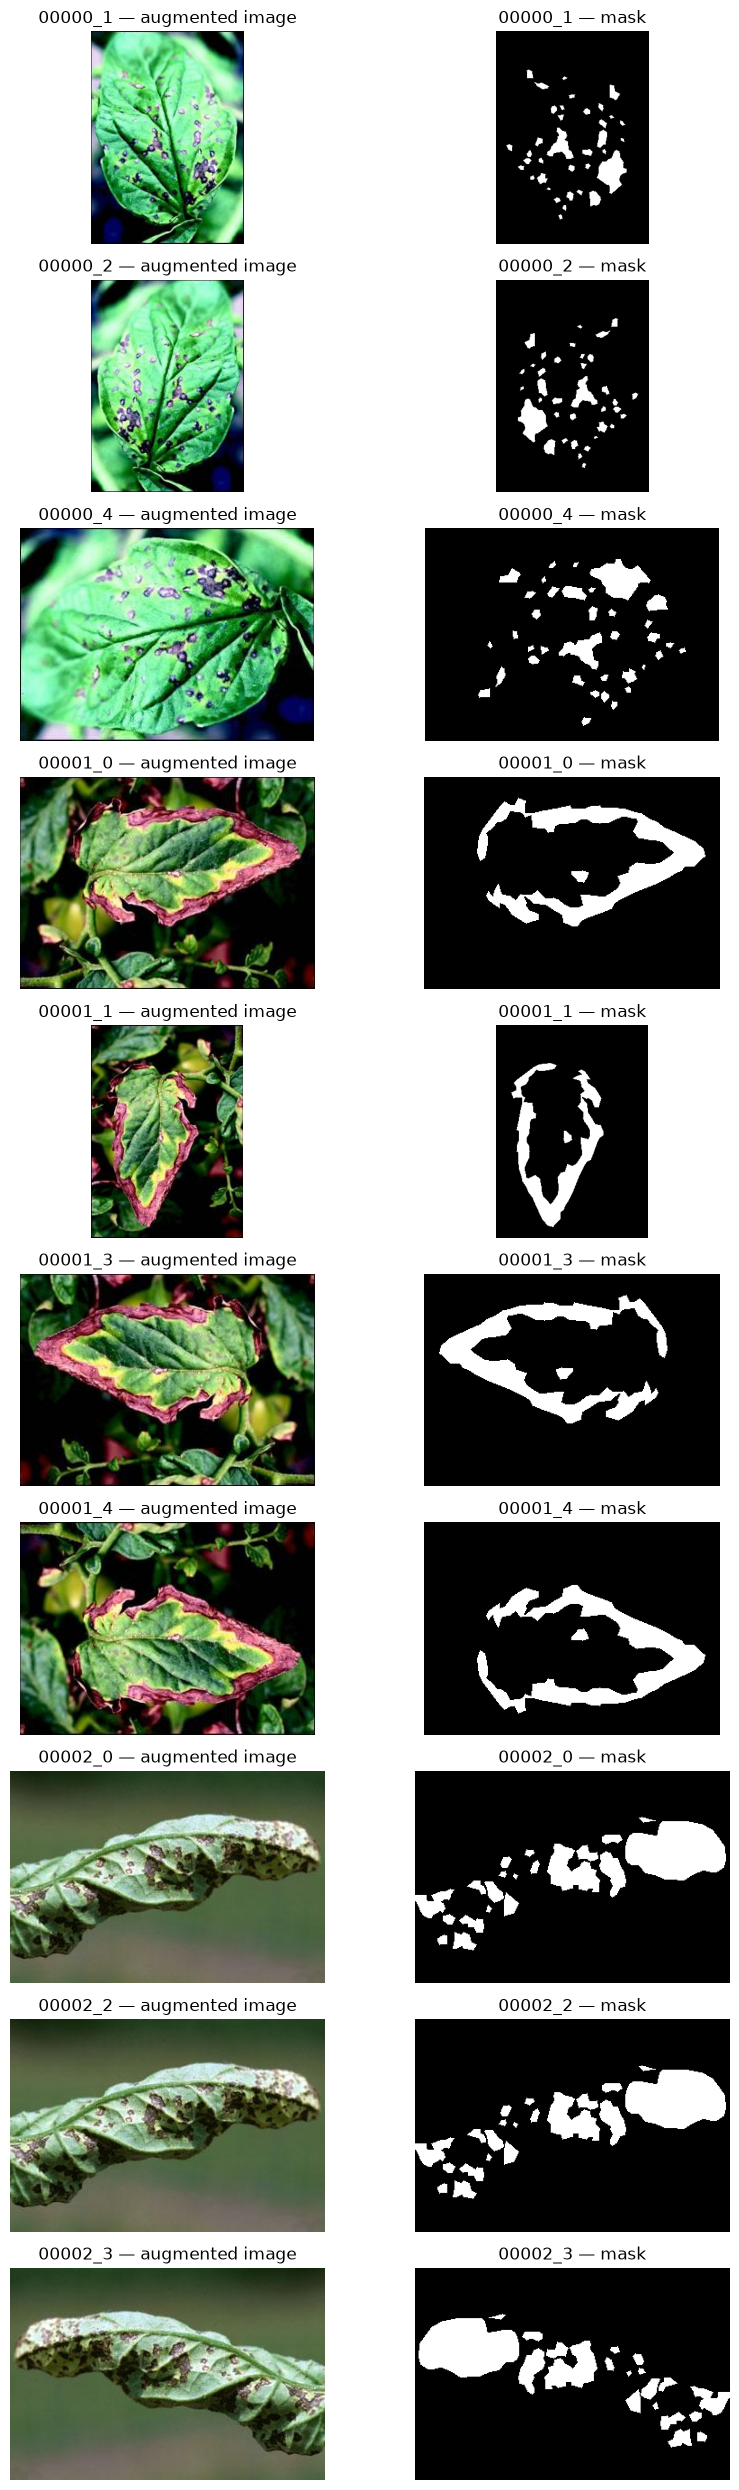

In [4]:
fig, axs = plt.subplots(nrows=10, ncols=2, figsize=(9, 25))

for i, image_file in enumerate(augmented_image_files[:10]):
    im, mask = load_pair(image_file)

    axs[i,0].imshow(im)
    axs[i,0].set_title(image_file.stem + " — augmented image")
    axs[i,0].axis("off")

    axs[i,1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axs[i,1].set_title(image_file.stem + " — mask")
    axs[i,1].axis("off")

plt.tight_layout()

## 1. Decide on the training / validation / testing split

We split **original source images**, not augmented files and not individual pixels. This is important because several augmented files can come from the same original image. If one version were used for training and another version of the same source image for validation or testing, the evaluation could be too optimistic.

We use:

- **Training:** all augmented versions of 80% of the 498 original training images.
- **Validation:** the original, unaugmented 20% of the 498 original training images.
- **Testing:** the 90 original images in the supplied validation folder.

The augmented versions are collected from both `aug_data/train_*` and `aug_data/valid_*`, but only when their source image belongs to the training split. This is necessary because the supplied augmented train and valid folders contain versions of some of the same source images.

In [5]:
from sklearn.model_selection import train_test_split

# First split the ORIGINAL training images by source image.
train_source_files, val_files = train_test_split(
    train_image_files, test_size=0.2, random_state=42
)

# The supplied original validation folder is kept as the final test set.
test_files = valid_image_files

train_source_ids = {f.stem for f in train_source_files}
val_stems = {f.stem for f in val_files}
test_stems = {f.stem for f in test_files}

# Use every augmented version of the training source images only.
# Augmented files from validation/test source images are excluded.
train_files = [
    f for f in augmented_image_files
    if get_source_id(f) in train_source_ids
]

train_augmented_source_ids = {get_source_id(f) for f in train_files}

print("Original source images reserved for training:", len(train_source_files))
print("Augmented training image/mask pairs:", len(train_files))
print("Original validation images:", len(val_files))
print("Original testing images:", len(test_files))

# Confirm that the augmented training set contains all five versions
# of every selected training source image.
assert train_augmented_source_ids == train_source_ids
assert len(train_files) == 5 * len(train_source_files)

# Most importantly, no original source image appears in more than one split.
assert train_augmented_source_ids.isdisjoint(val_stems)
assert train_augmented_source_ids.isdisjoint(test_stems)
assert val_stems.isdisjoint(test_stems)

print("Source-level split check passed: no source image is shared across splits.")

Original source images reserved for training: 398
Augmented training image/mask pairs: 1990
Original validation images: 100
Original testing images: 90
Source-level split check passed: no source image is shared across splits.


## 1.1: Classifier using only the RGB values of one pixel

We first use a very simple feature vector. Each sample is one pixel, and its three features are its red, green and blue values.

For each **augmented training image**, we randomly extract a fixed number of pixels. The class of a sampled pixel is obtained from the corresponding augmented mask at exactly the same coordinates. Validation and testing samples are extracted from the original, unaugmented images.

We use 50 pixels per image, as in the example proposed in the project description. Since foreground pixels are less frequent than background pixels, we use a balanced logistic regression classifier.

In [6]:
# Each sample is one pixel: its RGB values and the mask value at the same location.
def build_pixel_dataset(image_files, samples_per_image=50, random_state=0):
    rng = np.random.default_rng(random_state)
    X, y = [], []

    for image_file in image_files:
        im, mask = load_pair(image_file)
        indices = rng.choice(mask.size, samples_per_image, replace=False)
        X.append(im.reshape(-1,3)[indices])
        y.append(mask.ravel()[indices])

    return np.vstack(X), np.hstack(y).astype(np.uint8)


X_train_rgb, y_train_rgb = build_pixel_dataset(
    train_files, samples_per_image=50, random_state=0
)
X_val_rgb, y_val_rgb = build_pixel_dataset(
    val_files, samples_per_image=50, random_state=1
)
X_test_rgb, y_test_rgb = build_pixel_dataset(
    test_files, samples_per_image=50, random_state=2
)

print("Training feature and label shapes:", X_train_rgb.shape, y_train_rgb.shape)
print("Validation feature and label shapes:", X_val_rgb.shape, y_val_rgb.shape)
print("Testing feature and label shapes:", X_test_rgb.shape, y_test_rgb.shape)
print("Training class distribution [background, foreground]:",
      np.bincount(y_train_rgb, minlength=2))

Training feature and label shapes: (99500, 3) (99500,)
Validation feature and label shapes: (5000, 3) (5000,)
Testing feature and label shapes: (4500, 3) (4500,)
Training class distribution [background, foreground]: [83408 16092]


### Train a logistic regression classifier

The classifier receives three numbers (R, G and B) and predicts whether the pixel belongs to class 0 or class 1.

In [7]:
import sklearn.linear_model
import sklearn.metrics
from sklearn.metrics import ConfusionMatrixDisplay

clf_rgb = sklearn.linear_model.LogisticRegression(
    max_iter=500,
    class_weight="balanced"
)

clf_rgb.fit(X_train_rgb, y_train_rgb)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",500
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to 

### Evaluate the classifier

We report accuracy, balanced accuracy, precision and recall. We also display the confusion matrix.

Accuracy alone can be misleading when one class is more frequent than the other. The confusion matrix helps us see how well the classifier recognizes foreground pixels.

RGB logistic regression — validation set
Accuracy: 0.7188
Balanced accuracy: 0.7434942479190267
              precision    recall  f1-score   support

  background       0.94      0.71      0.81      4181
  foreground       0.34      0.78      0.48       819

    accuracy                           0.72      5000
   macro avg       0.64      0.74      0.64      5000
weighted avg       0.84      0.72      0.75      5000



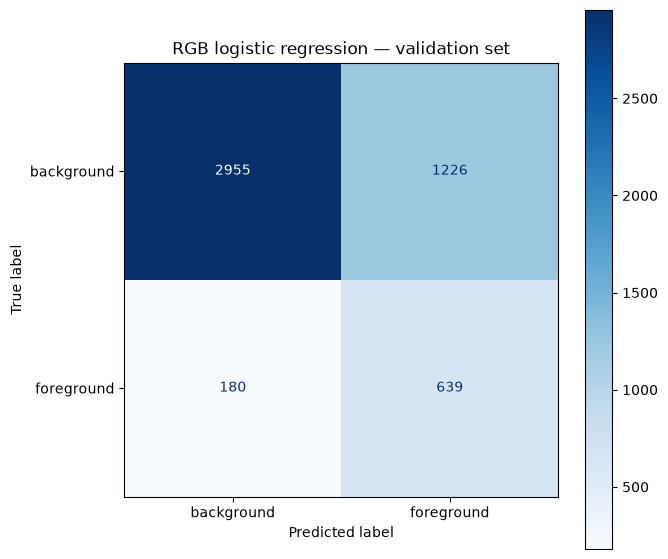

In [8]:
def evaluate_classifier(clf, X, y, title):
    y_pred = clf.predict(X)

    print(title)
    print("Accuracy:", sklearn.metrics.accuracy_score(y, y_pred))
    print("Balanced accuracy:", sklearn.metrics.balanced_accuracy_score(y, y_pred))
    print(sklearn.metrics.classification_report(
        y, y_pred, target_names=["background", "foreground"], zero_division=0
    ))

    cm = sklearn.metrics.confusion_matrix(y, y_pred, labels=[0,1])
    ConfusionMatrixDisplay(cm, display_labels=["background", "foreground"]).plot(
        cmap="Blues", values_format="d"
    )
    plt.title(title)
    plt.show()

    return {
        "accuracy": sklearn.metrics.accuracy_score(y, y_pred),
        "balanced_accuracy": sklearn.metrics.balanced_accuracy_score(y, y_pred)
    }


metrics_rgb_val = evaluate_classifier(
    clf_rgb, X_val_rgb, y_val_rgb, "RGB logistic regression — validation set"
)

### Final test evaluation for the RGB classifier

We use the test set only after training and validation. The test set contains images that were not used to train the classifier.

RGB logistic regression — test set
Accuracy: 0.7733333333333333
Balanced accuracy: 0.7707959210547259
              precision    recall  f1-score   support

  background       0.94      0.77      0.85      3766
  foreground       0.40      0.77      0.52       734

    accuracy                           0.77      4500
   macro avg       0.67      0.77      0.69      4500
weighted avg       0.86      0.77      0.80      4500



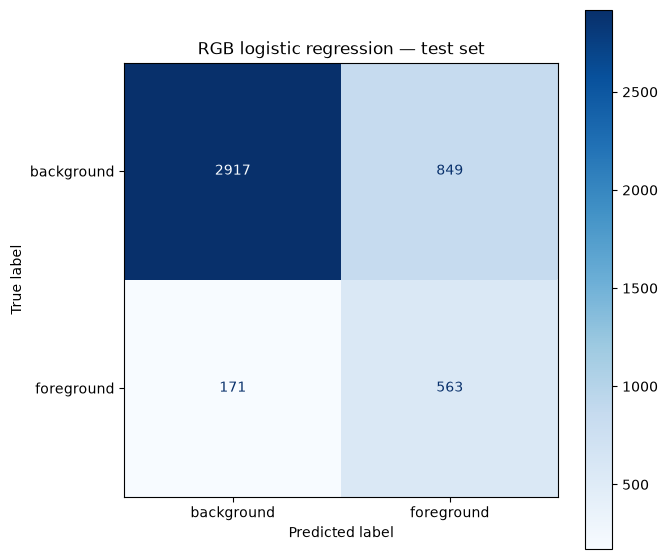

In [9]:
metrics_rgb_test = evaluate_classifier(
    clf_rgb, X_test_rgb, y_test_rgb, "RGB logistic regression — test set"
)

# TBD AUC , RBG AS BASELINE   USE ALREADY MADE PATCH SET FOR CONVUTION MODEL AUC FOR EVRY MODEL ,  EXTREME LATER TIME TRY MODELS WITHOUT PATCH

### Apply the classifier to every pixel of a test image

Once the classifier is trained, we can apply it to every pixel of an image. We reshape the image into a list of RGB vectors, classify them, and reshape the predictions back into an image.

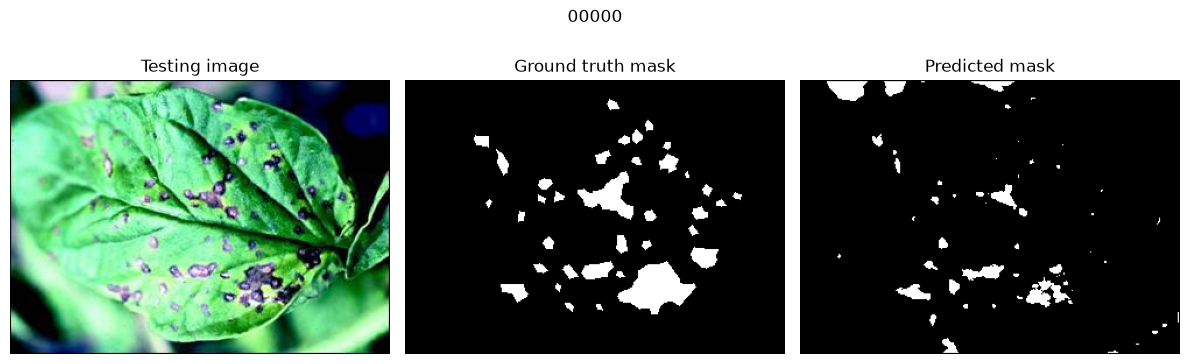

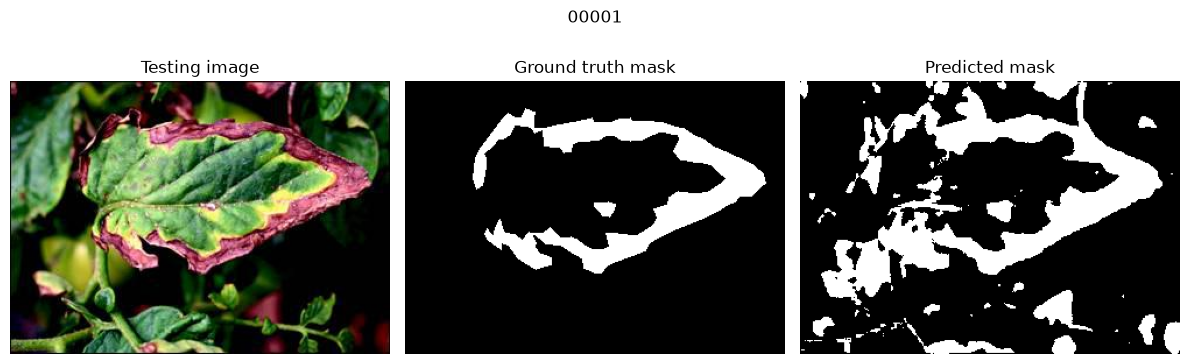

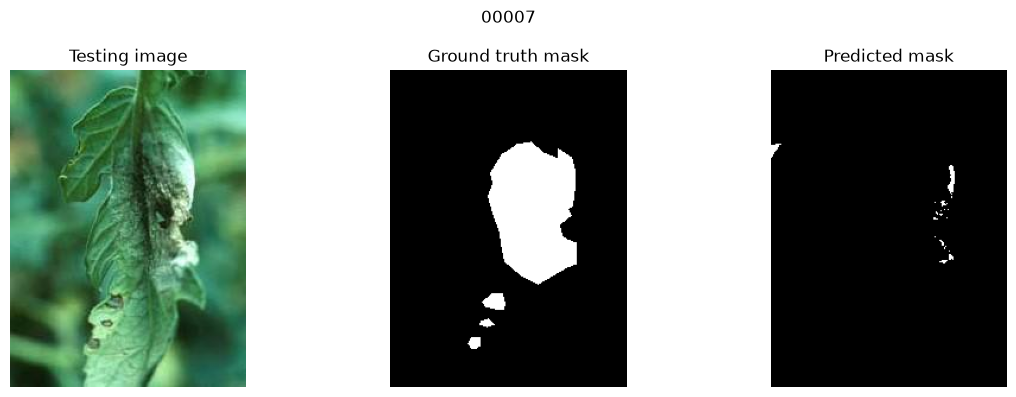

In [10]:
def predict_pixel_mask(clf, im):
    h, w = im.shape[:2]
    predicted = clf.predict(im.reshape(-1,3))
    return predicted.reshape(h,w)


for image_file in test_files[:3]:
    im, mask = load_pair(image_file)
    predicted_mask = predict_pixel_mask(clf_rgb, im)

    fig, axs = plt.subplots(ncols=3, figsize=(12,4))
    axs[0].imshow(im)
    axs[0].set_title("Testing image")
    axs[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axs[1].set_title("Ground truth mask")
    axs[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axs[2].set_title("Predicted mask")

    for ax in axs:
        ax.axis("off")

    plt.suptitle(image_file.stem)
    plt.tight_layout()

## 1.2: Use a small image patch around the pixel

The RGB value of one pixel contains very little context. We now use a 15×15 RGB patch centred on the pixel.

The class is still the class of the **central pixel**, read from the segmentation mask. We sample 25 pixels per image here (rather than 50) because each patch has 675 features. The patch is flattened into a one-dimensional feature vector, so each sample has `15 * 15 * 3 = 675` features.

Training patches are sampled from the augmented training images. Validation and test patches are sampled from the original, unaugmented images.

At the image borders, we use reflection padding so that every pixel has a complete patch.

In [11]:
PATCH_SIZE = 15

def build_patch_dataset(image_files, samples_per_image=50,
                        patch_size=PATCH_SIZE, random_state=0):
    rng = np.random.default_rng(random_state)
    radius = patch_size // 2
    X, y = [], []

    for image_file in image_files:
        im, mask = load_pair(image_file)
        indices = rng.choice(mask.size, samples_per_image, replace=False)
        rows, cols = np.unravel_index(indices, mask.shape)

        padded = np.pad(im, ((radius,radius), (radius,radius), (0,0)), mode="reflect")
        patches = [padded[r:r+patch_size, c:c+patch_size]
                   for r,c in zip(rows, cols)]

        X.append(np.array(patches).reshape(samples_per_image, -1))
        y.append(mask.ravel()[indices])

    return np.vstack(X), np.hstack(y).astype(np.uint8)


X_train_patch, y_train_patch = build_patch_dataset(
    train_files, samples_per_image=25, random_state=10
)
X_val_patch, y_val_patch = build_patch_dataset(
    val_files, samples_per_image=25, random_state=11
)
X_test_patch, y_test_patch = build_patch_dataset(
    test_files, samples_per_image=25, random_state=12
)

print("Patch feature shape:", X_train_patch.shape)
print("Expected number of features:", PATCH_SIZE * PATCH_SIZE * 3)
print("Training labels:", np.bincount(y_train_patch, minlength=2))

Patch feature shape: (49750, 675)
Expected number of features: 675
Training labels: [41887  7863]


### Train an SVM classifier on the raw patch values

We start with a linear support vector machine. It is still a relatively simple classifier, but now it can use the colour information in a neighbourhood around each pixel.

15x15 patch + linear SVM — validation set
Accuracy: 0.7372
Balanced accuracy: 0.7325499622309161
              precision    recall  f1-score   support

  background       0.93      0.74      0.82      2063
  foreground       0.37      0.73      0.49       437

    accuracy                           0.74      2500
   macro avg       0.65      0.73      0.66      2500
weighted avg       0.83      0.74      0.76      2500



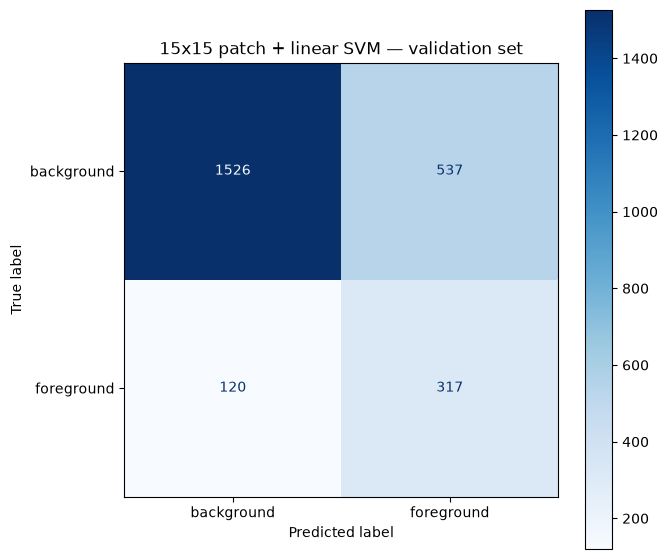

In [12]:
from sklearn.svm import LinearSVC

clf_patch_svm = LinearSVC(
    class_weight="balanced",
    dual=False,
    max_iter=3000,
    random_state=0
)

clf_patch_svm.fit(X_train_patch, y_train_patch)

metrics_patch_svm_val = evaluate_classifier(
    clf_patch_svm, X_val_patch, y_val_patch,
    "15x15 patch + linear SVM — validation set"
)

15x15 patch + linear SVM — test set
Accuracy: 0.7751111111111111
Balanced accuracy: 0.7558065761888999
              precision    recall  f1-score   support

  background       0.94      0.78      0.86      1908
  foreground       0.38      0.73      0.50       342

    accuracy                           0.78      2250
   macro avg       0.66      0.76      0.68      2250
weighted avg       0.86      0.78      0.80      2250



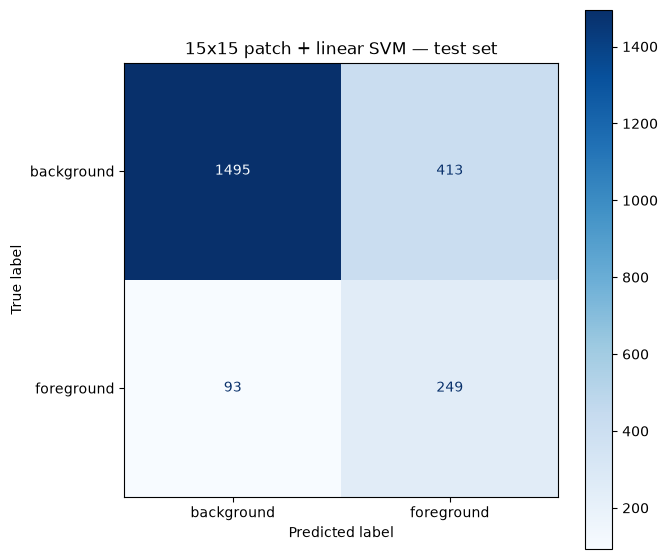

In [13]:
metrics_patch_svm_test = evaluate_classifier(
    clf_patch_svm, X_test_patch, y_test_patch,
    "15x15 patch + linear SVM — test set"
)

### Try a random forest classifier

A random forest is another option proposed in the project description. We use a moderate number of trees to keep the experiment manageable.

15x15 patch + random forest — validation set
Accuracy: 0.828
Balanced accuracy: 0.6865654092870905
              precision    recall  f1-score   support

  background       0.89      0.90      0.90      2063
  foreground       0.51      0.47      0.49       437

    accuracy                           0.83      2500
   macro avg       0.70      0.69      0.69      2500
weighted avg       0.82      0.83      0.83      2500



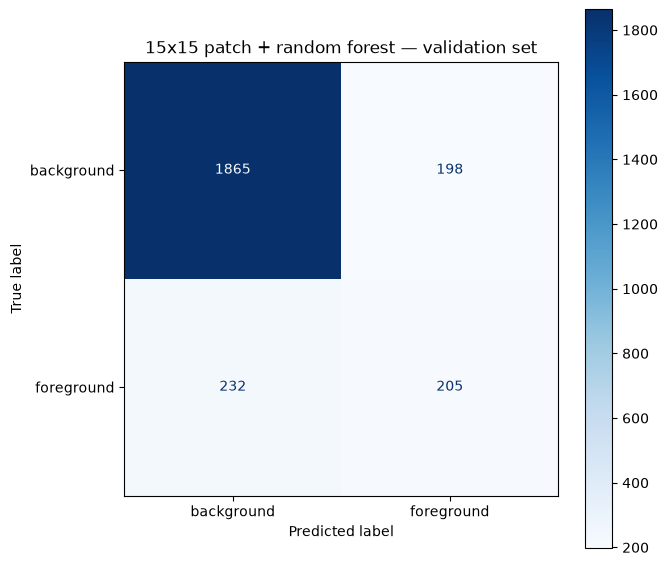

In [14]:
from sklearn.ensemble import RandomForestClassifier

clf_patch_rf = RandomForestClassifier(
    n_estimators=40,
    max_depth=16,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=0
)

clf_patch_rf.fit(X_train_patch, y_train_patch)

metrics_patch_rf_val = evaluate_classifier(
    clf_patch_rf, X_val_patch, y_val_patch,
    "15x15 patch + random forest — validation set"
)

15x15 patch + random forest — test set
Accuracy: 0.844
Balanced accuracy: 0.6848311817279047
              precision    recall  f1-score   support

  background       0.90      0.91      0.91      1908
  foreground       0.49      0.46      0.47       342

    accuracy                           0.84      2250
   macro avg       0.69      0.68      0.69      2250
weighted avg       0.84      0.84      0.84      2250



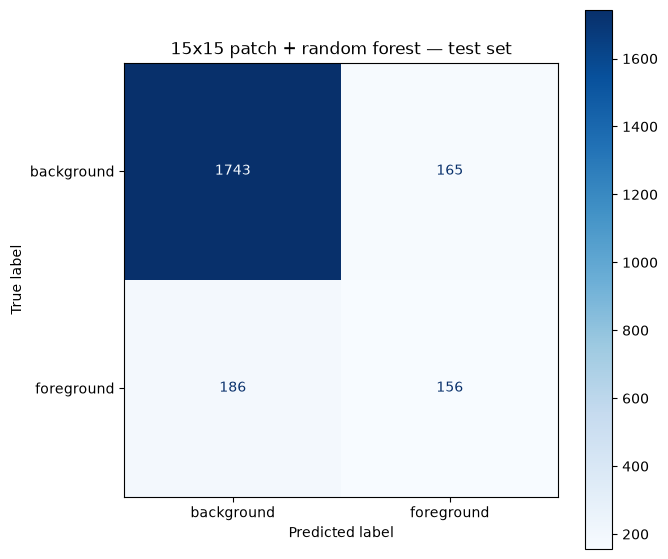

In [15]:
metrics_patch_rf_test = evaluate_classifier(
    clf_patch_rf, X_test_patch, y_test_patch,
    "15x15 patch + random forest — test set"
)

### Add simple features computed from the patch

In addition to the raw RGB values, we can compute:

- the average R, G and B values in the patch;
- the variance of the grayscale intensity in the patch;
- the average gradient magnitude in the patch.

We concatenate these features to the flattened RGB patch. This is one way to test whether simple summary features improve the result.

In [16]:
def add_patch_summary_features(X, patch_size=PATCH_SIZE):
    patches = X.reshape(-1, patch_size, patch_size, 3)

    rgb_mean = np.mean(patches, axis=(1,2))

    gray = np.mean(patches, axis=3)
    gray_variance = np.var(gray, axis=(1,2))[:,np.newaxis]

    gy, gx = np.gradient(gray, axis=(1,2))
    gradient_magnitude = np.sqrt(gx**2 + gy**2)
    gradient_mean = np.mean(gradient_magnitude, axis=(1,2))[:,np.newaxis]

    return np.concatenate(
        [X, rgb_mean, gray_variance, gradient_mean],
        axis=1
    )


X_train_patch_features = add_patch_summary_features(X_train_patch)
X_val_patch_features = add_patch_summary_features(X_val_patch)
X_test_patch_features = add_patch_summary_features(X_test_patch)

print("Raw patch feature count:", X_train_patch.shape[1])
print("Patch + summary feature count:", X_train_patch_features.shape[1])

Raw patch feature count: 675
Patch + summary feature count: 680


15x15 patch + summary features + linear SVM — validation set
Accuracy: 0.7564
Balanced accuracy: 0.7513978997949045
              precision    recall  f1-score   support

  background       0.93      0.76      0.84      2063
  foreground       0.40      0.74      0.52       437

    accuracy                           0.76      2500
   macro avg       0.66      0.75      0.68      2500
weighted avg       0.84      0.76      0.78      2500



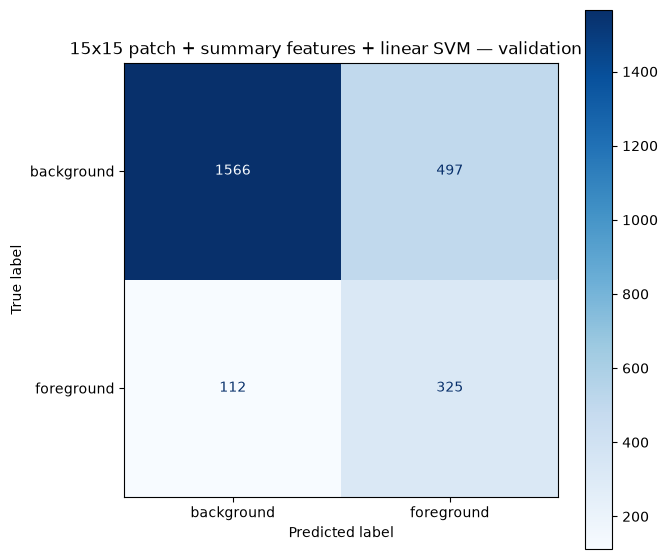

In [17]:
clf_patch_features = LinearSVC(
    class_weight="balanced",
    dual=False,
    max_iter=3000,
    random_state=0
)

clf_patch_features.fit(X_train_patch_features, y_train_patch)

metrics_patch_features_val = evaluate_classifier(
    clf_patch_features, X_val_patch_features, y_val_patch,
    "15x15 patch + summary features + linear SVM — validation set"
)

15x15 patch + summary features + linear SVM — test set
Accuracy: 0.7928888888888889
Balanced accuracy: 0.7818878958402296
              precision    recall  f1-score   support

  background       0.95      0.80      0.87      1908
  foreground       0.40      0.77      0.53       342

    accuracy                           0.79      2250
   macro avg       0.68      0.78      0.70      2250
weighted avg       0.87      0.79      0.82      2250



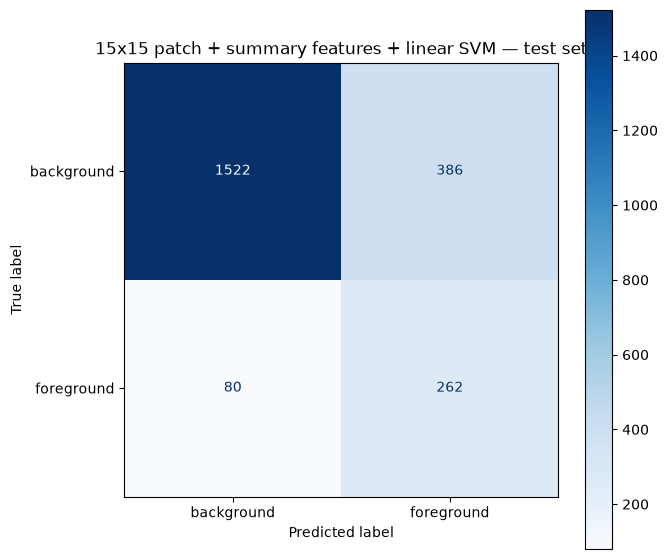

In [18]:
metrics_patch_features_test = evaluate_classifier(
    clf_patch_features, X_test_patch_features, y_test_patch,
    "15x15 patch + summary features + linear SVM — test set"
)

### Apply a patch classifier to every pixel of a test image

For every pixel, we extract its 15×15 neighbourhood and classify it. We process a few rows at a time so that we do not have to store all image patches in memory at once.

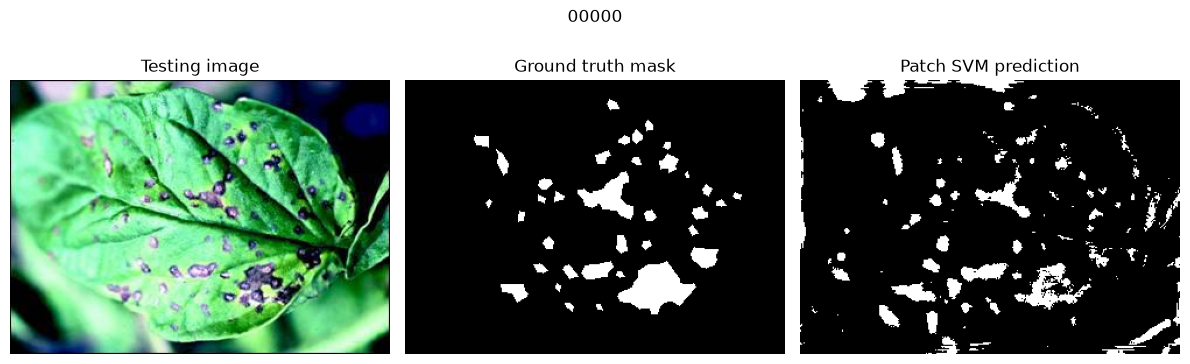

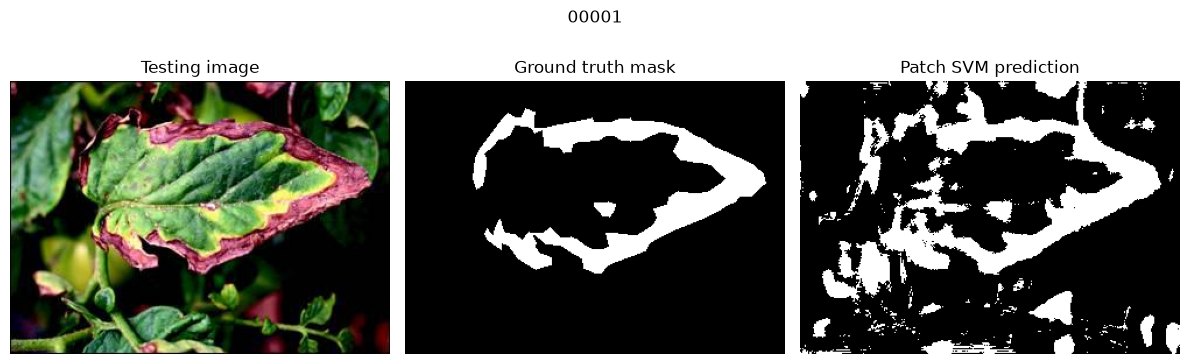

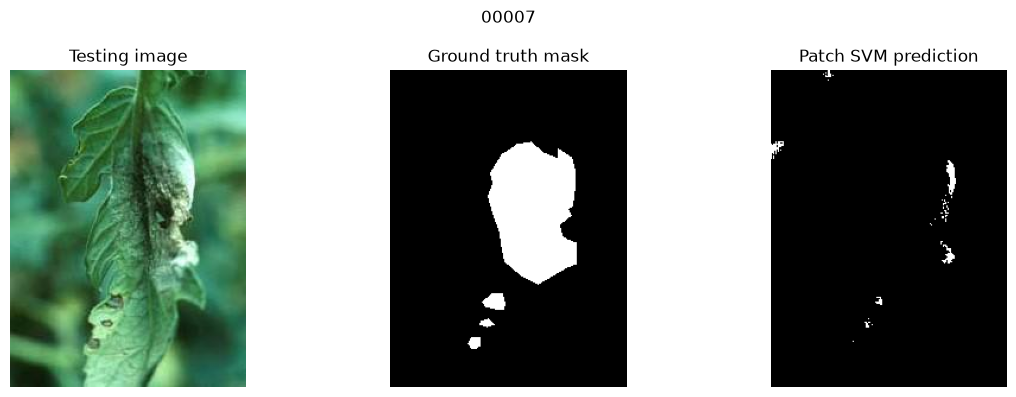

In [19]:
def predict_patch_mask(clf, im, patch_size=PATCH_SIZE, rows_per_batch=8):
    assert patch_size % 2 == 1

    radius = patch_size // 2
    h, w = im.shape[:2]

    padded = np.pad(
        im,
        ((radius,radius), (radius,radius), (0,0)),
        mode="reflect"
    )

    # Shape of windows: (height, width, channels, patch_height, patch_width)
    windows = np.lib.stride_tricks.sliding_window_view(
        padded, (patch_size,patch_size), axis=(0,1)
    )

    predicted = np.zeros((h,w), dtype=np.uint8)

    for r0 in range(0,h,rows_per_batch):
        r1 = min(r0 + rows_per_batch, h)

        batch = windows[r0:r1].transpose(0,1,3,4,2)
        batch = batch.reshape(-1, patch_size * patch_size * 3)

        predicted[r0:r1,:] = clf.predict(batch).reshape(r1-r0,w)

    return predicted


for image_file in test_files[:3]:
    im, mask = load_pair(image_file)
    predicted_mask = predict_patch_mask(clf_patch_svm, im)

    fig, axs = plt.subplots(ncols=3, figsize=(12,4))
    axs[0].imshow(im)
    axs[0].set_title("Testing image")
    axs[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axs[1].set_title("Ground truth mask")
    axs[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axs[2].set_title("Patch SVM prediction")

    for ax in axs:
        ax.axis("off")

    plt.suptitle(image_file.stem)
    plt.tight_layout()

## 1.3: Use a simple MLP on the flattened image patch

The last experiment uses a small feedforward neural network. The input is still the flattened 15×15 RGB patch, and the output is the class of its central pixel.

The MLP is trained using the augmented training patches. Validation and test patches come from the original, unaugmented images.

`MLPClassifier` does not have a `class_weight` parameter. To make the two classes equally represented during training, we randomly undersample the more frequent class. The validation and test sets are not balanced; they keep the original pixel distribution.

In [20]:
def balance_training_data(X, y, random_state=0):
    rng = np.random.default_rng(random_state)

    indices_0 = np.where(y == 0)[0]
    indices_1 = np.where(y == 1)[0]

    n = min(len(indices_0), len(indices_1))

    chosen_0 = rng.choice(indices_0, size=n, replace=False)
    chosen_1 = rng.choice(indices_1, size=n, replace=False)

    chosen = np.concatenate([chosen_0, chosen_1])
    rng.shuffle(chosen)

    return X[chosen], y[chosen]


X_train_patch_balanced, y_train_patch_balanced = balance_training_data(
    X_train_patch, y_train_patch, random_state=20
)

print("Balanced training feature shape:", X_train_patch_balanced.shape)
print("Balanced training labels:", np.bincount(y_train_patch_balanced, minlength=2))

Balanced training feature shape: (15726, 675)
Balanced training labels: [7863 7863]


In [21]:
from sklearn.neural_network import MLPClassifier

clf_patch_mlp = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="adam",
    batch_size=256,
    max_iter=25,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=0,
    verbose=True
)

clf_patch_mlp.fit(X_train_patch_balanced, y_train_patch_balanced)

Iteration 1, loss = 0.61378490
Validation score: 0.741894
Iteration 2, loss = 0.56337052
Validation score: 0.741894
Iteration 3, loss = 0.54995889
Validation score: 0.758423
Iteration 4, loss = 0.54340306
Validation score: 0.757788
Iteration 5, loss = 0.54223646
Validation score: 0.749523
Iteration 6, loss = 0.54702833
Validation score: 0.750159
Iteration 7, loss = 0.53314500
Validation score: 0.764145
Iteration 8, loss = 0.52972946
Validation score: 0.758423
Iteration 9, loss = 0.52796263
Validation score: 0.759059
Iteration 10, loss = 0.52667449
Validation score: 0.763509
Iteration 11, loss = 0.52368089
Validation score: 0.760966
Iteration 12, loss = 0.52961328
Validation score: 0.760966
Iteration 13, loss = 0.51958093
Validation score: 0.752066
Validation score did not improve more than tol=0.000100 for 5 consecutive epochs. Stopping.


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64,)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",25
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",0
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by at least``tol`` for ``n_iter_no_change`` consecutive epochs. The split isstratified, except in a multilabel setting.If early stopping is False, then the training stops when the trainingloss does not improve by more than ``tol`` for ``n_iter_no_change``consecutive passes over the training set.Only effective when solver='sgd' or 'adam'.",True
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",5
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score b

### Evaluate the MLP

We evaluate on the same validation and test samples used for the other patch classifiers. This allows us to compare the models on the same sampled pixels.

15x15 patch + MLP — validation set
Accuracy: 0.688
Balanced accuracy: 0.7514361680297184
              precision    recall  f1-score   support

  background       0.95      0.65      0.78      2063
  foreground       0.34      0.85      0.49       437

    accuracy                           0.69      2500
   macro avg       0.65      0.75      0.63      2500
weighted avg       0.85      0.69      0.73      2500



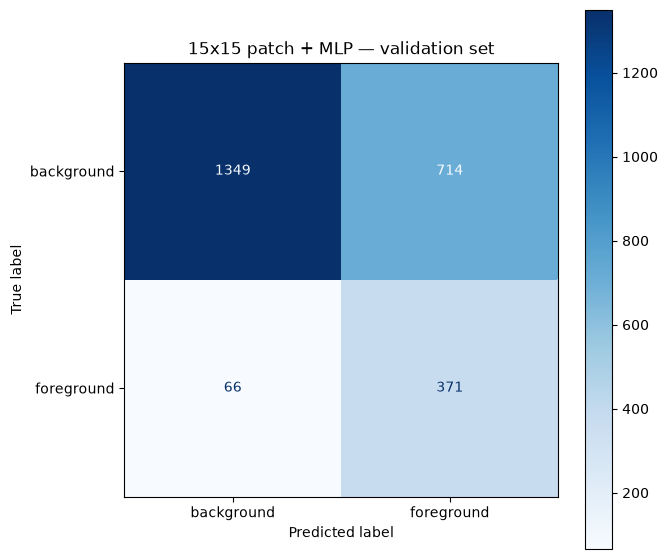

15x15 patch + MLP — test set
Accuracy: 0.7213333333333334
Balanced accuracy: 0.7492965905329361
              precision    recall  f1-score   support

  background       0.95      0.71      0.81      1908
  foreground       0.33      0.79      0.46       342

    accuracy                           0.72      2250
   macro avg       0.64      0.75      0.64      2250
weighted avg       0.85      0.72      0.76      2250



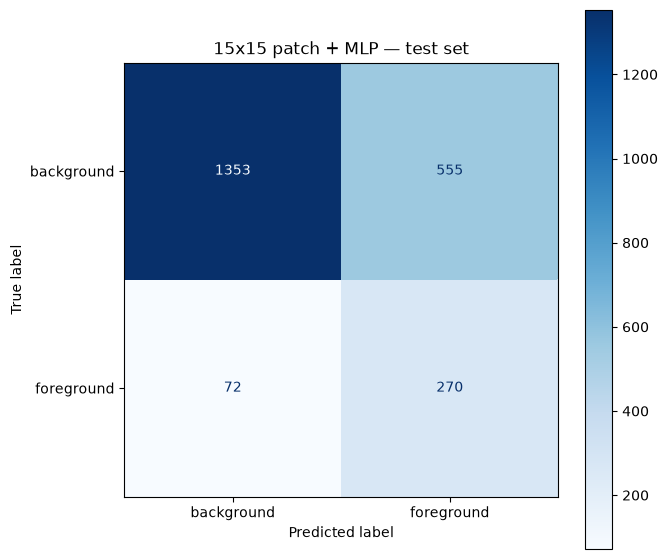

In [22]:
metrics_patch_mlp_val = evaluate_classifier(
    clf_patch_mlp, X_val_patch, y_val_patch,
    "15x15 patch + MLP — validation set"
)

metrics_patch_mlp_test = evaluate_classifier(
    clf_patch_mlp, X_test_patch, y_test_patch,
    "15x15 patch + MLP — test set"
)

### Apply the trained MLP to complete test images

As before, the class of every pixel is predicted from its local 15×15 patch.

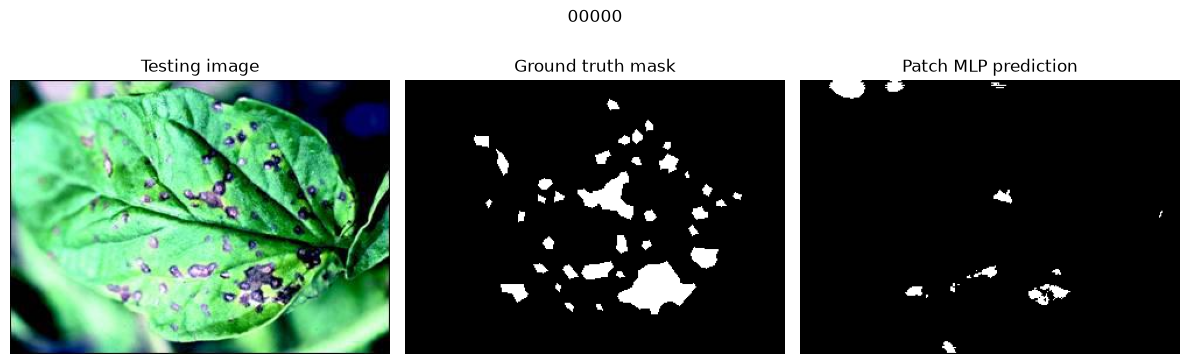

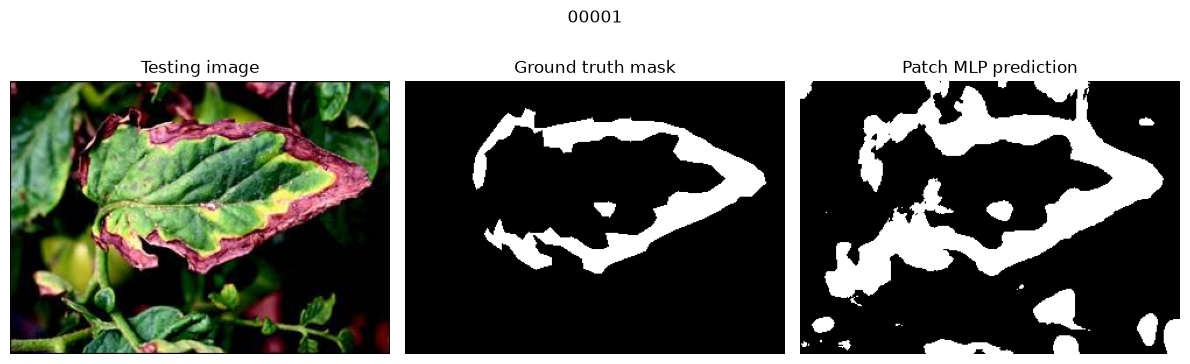

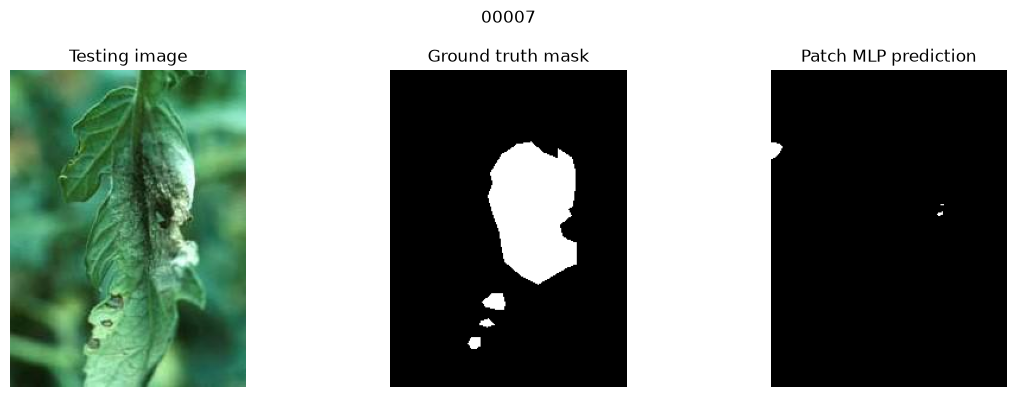

In [23]:
for image_file in test_files[:3]:
    im, mask = load_pair(image_file)
    predicted_mask = predict_patch_mask(clf_patch_mlp, im)

    fig, axs = plt.subplots(ncols=3, figsize=(12,4))
    axs[0].imshow(im)
    axs[0].set_title("Testing image")
    axs[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axs[1].set_title("Ground truth mask")
    axs[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
    axs[2].set_title("Patch MLP prediction")

    for ax in axs:
        ax.axis("off")

    plt.suptitle(image_file.stem)
    plt.tight_layout()

## Part 1 — Results to discuss

After running the notebook, compare the validation results for:

1. RGB values of the central pixel + logistic regression.
2. 15×15 patch + linear SVM.
3. 15×15 patch + random forest.
4. 15×15 patch + SVM using raw and summary features.
5. 15×15 patch + MLP.

Discuss accuracy together with the foreground precision and recall. Also compare the predicted masks with the ground-truth masks. The final test set is used for the final evaluation, after choosing the approach using validation results.